In [ ]:
import sys, platform
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import sklearn

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Kernel Python:", sys.executable)
print("Python", sys.version.split()[0], platform.machine())
print("TF", tf.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)

In [ ]:
from pathlib import Path

CSV_PATH = Path("data/icml_face_data.csv")
EMOTIONS = ["angry", "disgust", "fear", "happy", "sad", "surprise", "neutral"]

df = pd.read_csv(CSV_PATH)
df.columns = df.columns.str.strip()

# One long string of all pixels -> numbers -> one 48x48 grid per row
X_all = np.array(" ".join(df["pixels"]).split(), dtype=np.uint8).reshape(-1, 48, 48)
y_all = df["emotion"].to_numpy()

print("Columns:", list(df.columns))
print("X_all:", X_all.shape, X_all.dtype, "| min", X_all.min(), "max", X_all.max())
print("y_all:", y_all.shape, "| labels present:", sorted(set(y_all)))
print("Usage values:", df["Usage"].unique())

In [ ]:
labels = df["emotion"].map(dict(enumerate(EMOTIONS)))   # 0 -> "angry", etc.

counts = pd.crosstab(labels, df["Usage"], margins=True, margins_name="Total")
counts = counts[["Training", "PublicTest", "PrivateTest", "Total"]]
counts["% of all"] = (counts["Total"] / len(df) * 100).round(1)
print(counts)

train_counts = counts.loc[EMOTIONS, "Training"]
print(f"\nImbalance (largest / smallest class in Training): "
      f"{train_counts.max()} / {train_counts.min()} = {train_counts.max() / train_counts.min():.1f}x")

In [ ]:
# --- Decision: drop the "disgust" class (label 1) ---
keep = (df["emotion"] != 1).to_numpy()           # True for every non-disgust row

df = df[keep].reset_index(drop=True)
X_all = X_all[keep]

CLASSES = [e for e in EMOTIONS if e != "disgust"]  # ['angry','fear','happy','sad','surprise','neutral']
old_to_new = {old: CLASSES.index(name) for old, name in enumerate(EMOTIONS) if name != "disgust"}
y_all = df["emotion"].map(old_to_new).to_numpy()

print("Label mapping (old -> new):", old_to_new)
print("X_all:", X_all.shape, "| y_all:", y_all.shape, "| df rows:", len(df))
print("Images per class:", dict(zip(CLASSES, np.bincount(y_all))))
assert len(X_all) == len(y_all) == len(df) and set(y_all) == set(range(len(CLASSES)))

### Decision: drop the "disgust" class
- Disgust has only 436 training images (1.5% of the data), 16.5× fewer than happy. A CNN trained on it learns to almost never predict it.
- I dropped it, giving a 6-class problem: angry, fear, happy, sad, surprise, neutral. 547 images removed in total (35,340 remain).
- Training imbalance falls from 16.5× to 2.3× (happy 7,215 vs surprise 3,171).
- **Consequences:** results are not directly comparable to 7-class FER-2013 benchmarks. In the live demo, a disgusted face will be assigned one of the 6 remaining labels.

In [ ]:
rng = np.random.default_rng(SEED)
n_per_class = 8

fig, axes = plt.subplots(len(CLASSES), n_per_class, figsize=(n_per_class * 1.1, len(CLASSES) * 1.25))
for row, name in enumerate(CLASSES):
    idx = rng.choice(np.where(y_all == row)[0], n_per_class, replace=False)
    for col, i in enumerate(idx):
        ax = axes[row, col]
        ax.imshow(X_all[i], cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
    axes[row, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=10)

fig.suptitle("FER-2013: random samples per class (disgust dropped)", fontsize=11)
plt.tight_layout()
plt.savefig("figures/samples_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

is_train = (df["Usage"] == "Training").to_numpy()
is_test  = df["Usage"].isin(["PublicTest", "PrivateTest"]).to_numpy()

X_trval, y_trval = X_all[is_train], y_all[is_train]
X_test,  y_test  = X_all[is_test],  y_all[is_test]

X_train, X_val, y_train, y_val = train_test_split(
    X_trval, y_trval,
    test_size=0.10,          # 10% of Training -> validation
    stratify=y_trval,        # keep the same class proportions in both parts
    random_state=SEED,       # same split every run
)

for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name:<5} {X.shape}  labels {y.shape}")

dist = pd.DataFrame(
    {name: np.bincount(y, minlength=len(CLASSES)) / len(y) * 100
     for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]},
    index=CLASSES,
).round(1)
print("\nClass share (%) per split:\n", dist)

assert len(X_train) + len(X_val) + len(X_test) == len(X_all)

### Data split
- **Train / validation:** the official `Training` split, divided 90/10 with a stratified split (seed 42).
- **Test:** `PublicTest` + `PrivateTest` combined. **Not used until the final evaluation, and evaluated only once.**

In [ ]:
def preprocess(X):
    """uint8 (N, 48, 48) in 0-255  ->  float32 (N, 48, 48, 1) in 0-1.
    The webcam demo must apply exactly this same function."""
    return (X.astype("float32") / 255.0)[..., np.newaxis]

x_train, x_val, x_test = preprocess(X_train), preprocess(X_val), preprocess(X_test)

for name, x in [("x_train", x_train), ("x_val", x_val), ("x_test", x_test)]:
    print(f"{name:<8} {x.shape} {x.dtype}  range {x.min():.1f}-{x.max():.1f}  ({x.nbytes / 1e6:.0f} MB)")

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

results = {}   # model name -> (val accuracy, val macro-F1); we'll fill this as we go

def flat(X):
    return X.reshape(len(X), -1)      # (N, 48, 48) -> (N, 2304): one row of pixels per image

dummy = DummyClassifier(strategy="most_frequent").fit(flat(X_train), y_train)
pred = dummy.predict(flat(X_val))

results["Majority class"] = (accuracy_score(y_val, pred),
                             f1_score(y_val, pred, average="macro", zero_division=0))
print("Always predicts:", CLASSES[pred[0]])
print("Val accuracy: {:.3f} | Val macro-F1: {:.3f}".format(*results["Majority class"]))

In [ ]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logreg = make_pipeline(
    StandardScaler(),                         # each pixel -> mean 0, std 1 (fitted on train only)
    LogisticRegression(max_iter=300, C=0.1),  # C<1 = stronger regularisation against overfitting
)

t0 = time.time()
logreg.fit(flat(x_train), y_train)
print(f"Trained in {time.time() - t0:.0f} s")

train_acc = logreg.score(flat(x_train), y_train)
pred = logreg.predict(flat(x_val))
results["Logistic regression (pixels)"] = (accuracy_score(y_val, pred),
                                           f1_score(y_val, pred, average="macro"))

print(f"Train accuracy: {train_acc:.3f}")
print("Val accuracy:   {:.3f} | Val macro-F1: {:.3f}".format(*results["Logistic regression (pixels)"]))

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def conv_block(filters, name):
    """Two 3x3 convs (each + BatchNorm + ReLU), then halve the size, then dropout."""
    return keras.Sequential([
        layers.Conv2D(filters, 3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Conv2D(filters, 3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.MaxPooling2D(2),
        layers.Dropout(0.25),
    ], name=name)

def build_cnn(num_classes):
    augment = keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.03),          # ±0.03 of a full turn ≈ ±11°
        layers.RandomTranslation(0.1, 0.1),   # shift up to ±10% (≈ ±5 px)
    ], name="augmentation")

    return keras.Sequential([
        keras.Input(shape=(48, 48, 1)),
        augment,
        conv_block(32,  "block1"),   # 48x48 -> 24x24
        conv_block(64,  "block2"),   # 24x24 -> 12x12
        conv_block(128, "block3"),   # 12x12 -> 6x6
        conv_block(256, "block4"),   # 6x6   -> 3x3
        layers.Flatten(),
        layers.Dense(256, use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation="softmax"),
    ], name="emotion_cnn")

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model = build_cnn(len(CLASSES))
model.summary()

In [27]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

t0 = time.time()
model.fit(x_train, y_train,
          validation_data=(x_val, y_val),
          epochs=1, batch_size=64, verbose=1)
sec = time.time() - t0
print(f"\nOne epoch took {sec:.0f} s  ->  40 epochs ≈ {sec * 40 / 60:.0f} min")

398/398 ━━━━━━━━━━━━━━━━━━━━ 100s 245ms/step - accuracy: 0.2309 - loss: 2.0222 - val_accuracy: 0.3122 - val_loss: 1.6967

One epoch took 100 s  ->  40 epochs ≈ 67 min


In [28]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model = build_cnn(len(CLASSES))
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3,
                                      min_lr=1e-5, verbose=1),
    keras.callbacks.ModelCheckpoint("models/emotion_cnn.keras", monitor="val_loss",
                                    save_best_only=True),
    keras.callbacks.CSVLogger("models/training_log.csv"),
]

t0 = time.time()
history = model.fit(x_train, y_train,
                    validation_data=(x_val, y_val),
                    epochs=60, batch_size=64,
                    callbacks=callbacks, verbose=2)
print(f"\nTraining took {(time.time() - t0) / 60:.0f} min")

best = int(np.argmin(history.history["val_loss"]))
print(f"Best epoch: {best + 1} | val_loss {history.history['val_loss'][best]:.3f} "
      f"| val_accuracy {history.history['val_accuracy'][best]:.3f}")

Epoch 1/60
398/398 - 103s - 260ms/step - accuracy: 0.2680 - loss: 1.8739 - val_accuracy: 0.3122 - val_loss: 1.6967 - learning_rate: 1.0000e-03
Epoch 2/60
398/398 - 96s - 240ms/step - accuracy: 0.3833 - loss: 1.5604 - val_accuracy: 0.4325 - val_loss: 1.4465 - learning_rate: 1.0000e-03
Epoch 3/60
398/398 - 95s - 238ms/step - accuracy: 0.4620 - loss: 1.3582 - val_accuracy: 0.5244 - val_loss: 1.2359 - learning_rate: 1.0000e-03
Epoch 4/60
398/398 - 93s - 234ms/step - accuracy: 0.5049 - loss: 1.2626 - val_accuracy: 0.5286 - val_loss: 1.2112 - learning_rate: 1.0000e-03
Epoch 5/60
398/398 - 93s - 234ms/step - accuracy: 0.5272 - loss: 1.2100 - val_accuracy: 0.4929 - val_loss: 1.2831 - learning_rate: 1.0000e-03
Epoch 6/60
398/398 - 94s - 237ms/step - accuracy: 0.5493 - loss: 1.1650 - val_accuracy: 0.5668 - val_loss: 1.1489 - learning_rate: 1.0000e-03
Epoch 7/60
398/398 - 95s - 238ms/step - accuracy: 0.5606 - loss: 1.1406 - val_accuracy: 0.4961 - val_loss: 1.3170 - learning_rate: 1.0000e-03
Epoch

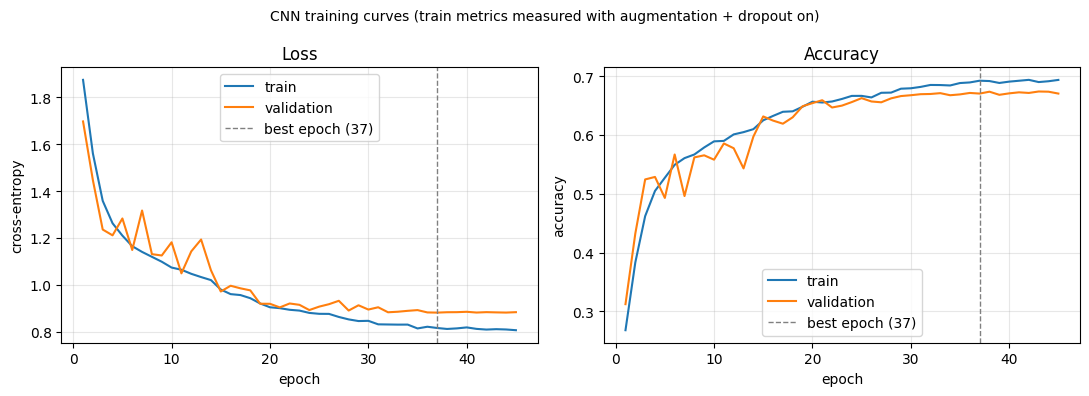

In [29]:
log = pd.read_csv("models/training_log.csv")
epochs = log["epoch"] + 1                      # CSV counts from 0; humans count from 1
best_epoch = int(log["val_loss"].idxmin()) + 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(epochs, log["loss"], label="train")
ax1.plot(epochs, log["val_loss"], label="validation")
ax1.set_title("Loss"); ax1.set_xlabel("epoch"); ax1.set_ylabel("cross-entropy")

ax2.plot(epochs, log["accuracy"], label="train")
ax2.plot(epochs, log["val_accuracy"], label="validation")
ax2.set_title("Accuracy"); ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy")

for ax in (ax1, ax2):
    ax.axvline(best_epoch, color="gray", linestyle="--", linewidth=1, label=f"best epoch ({best_epoch})")
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("CNN training curves (train metrics measured with augmentation + dropout on)", fontsize=10)
plt.tight_layout()
plt.savefig("figures/training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [30]:
best_model = keras.models.load_model("models/emotion_cnn.keras")

val_probs = best_model.predict(x_val, batch_size=256, verbose=0)   # (2828, 6) probabilities
val_pred = val_probs.argmax(axis=1)                                  # highest probability -> class

results["CNN (4 conv blocks)"] = (accuracy_score(y_val, val_pred),
                                  f1_score(y_val, val_pred, average="macro"))

scoreboard = pd.DataFrame(results, index=["val accuracy", "val macro-F1"]).T.round(3)
print(scoreboard)

                              val accuracy  val macro-F1
Majority class                       0.255         0.068
Logistic regression (pixels)         0.347         0.321
CNN (4 conv blocks)                  0.670         0.646


## 5. Final evaluation on the test set
Run once. The model was frozen before this point: no changes based on these results.

In [31]:
from sklearn.metrics import classification_report

test_probs = best_model.predict(x_test, batch_size=256, verbose=0)
test_pred = test_probs.argmax(axis=1)
np.save("models/test_predictions.npy", test_pred)        # analyse later without re-running

test_acc = accuracy_score(y_test, test_pred)
test_f1 = f1_score(y_test, test_pred, average="macro")
ci = 1.96 * np.sqrt(test_acc * (1 - test_acc) / len(y_test))

print(f"TEST accuracy: {test_acc:.3f}  (95% CI ±{ci:.3f})  |  macro-F1: {test_f1:.3f}  |  n = {len(y_test)}\n")

report = classification_report(y_test, test_pred, target_names=CLASSES, digits=3)
print(report)
Path("figures/test_classification_report.txt").write_text(report)

TEST accuracy: 0.664  (95% CI ±0.011)  |  macro-F1: 0.641  |  n = 7067

              precision    recall  f1-score   support

       angry      0.602     0.599     0.600       958
        fear      0.547     0.377     0.446      1024
       happy      0.870     0.881     0.875      1774
         sad      0.556     0.503     0.528      1247
    surprise      0.755     0.798     0.776       831
     neutral      0.550     0.715     0.622      1233

    accuracy                          0.664      7067
   macro avg      0.647     0.646     0.641      7067
weighted avg      0.662     0.664     0.659      7067



542

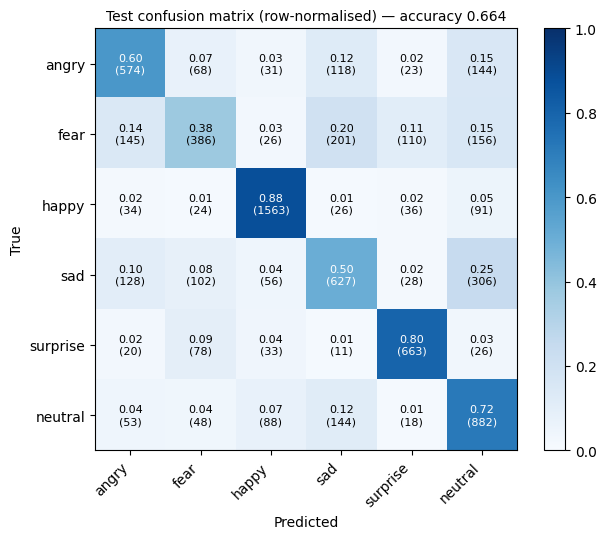

Top confusions (true -> predicted):
       sad -> neutral  24.5% of all sad faces  (306 images)
      fear -> sad      19.6% of all fear faces  (201 images)
      fear -> neutral  15.2% of all fear faces  (156 images)
     angry -> neutral  15.0% of all angry faces  (144 images)
      fear -> angry    14.2% of all fear faces  (145 images)
     angry -> sad      12.3% of all angry faces  (118 images)


In [32]:
from sklearn.metrics import confusion_matrix

test_pred = np.load("models/test_predictions.npy")       # the saved one-time predictions
cm = confusion_matrix(y_test, test_pred)                  # raw counts, rows = true, cols = predicted
cm_norm = cm / cm.sum(axis=1, keepdims=True)              # each row sums to 1 (= recall on the diagonal)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center",
                fontsize=8, color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Test confusion matrix (row-normalised) — accuracy {test_acc:.3f}", fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# The biggest specific mistakes, ranked
mistakes = [(cm_norm[i, j], CLASSES[i], CLASSES[j], cm[i, j])
            for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j]
print("Top confusions (true -> predicted):")
for share, true, pred, n in sorted(mistakes, reverse=True)[:6]:
    print(f"  {true:>8} -> {pred:<8} {share:5.1%} of all {true} faces  ({n} images)")

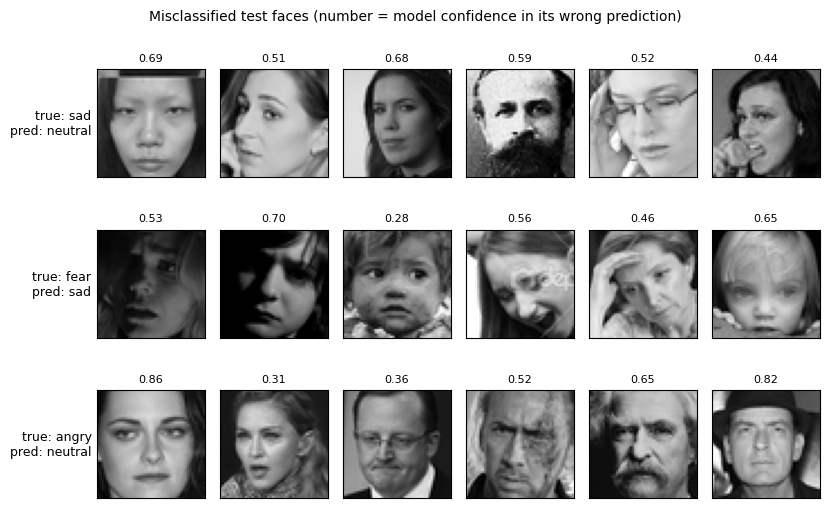

In [33]:
np.save("models/test_probs.npy", test_probs)    # keep probabilities too (still from the single test run)

pairs = [("sad", "neutral"), ("fear", "sad"), ("angry", "neutral")]   # the top confusions
n_show = 6
rng = np.random.default_rng(SEED)
confidence = test_probs.max(axis=1)

fig, axes = plt.subplots(len(pairs), n_show, figsize=(n_show * 1.4, len(pairs) * 1.8))
for row, (true_name, pred_name) in enumerate(pairs):
    t, p = CLASSES.index(true_name), CLASSES.index(pred_name)
    idx = np.where((y_test == t) & (test_pred == p))[0]
    pick = rng.choice(idx, n_show, replace=False)
    for col, i in enumerate(pick):
        ax = axes[row, col]
        ax.imshow(X_test[i], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{confidence[i]:.2f}", fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
    axes[row, 0].set_ylabel(f"true: {true_name}\npred: {pred_name}",
                            rotation=0, ha="right", va="center", fontsize=9)

fig.suptitle("Misclassified test faces (number = model confidence in its wrong prediction)", fontsize=10)
plt.tight_layout()
plt.savefig("figures/misclassified_examples.png", dpi=150, bbox_inches="tight")
plt.show()

### Results (test set, evaluated once, n = 7,067)
| Model | Val accuracy | Val macro-F1 |
|---|---|---|
| Majority class | 0.255 | 0.068 |
| Logistic regression (raw pixels) | 0.347 | 0.321 |
| CNN (4 conv blocks) | 0.670 | 0.646 |

**CNN on the test set: accuracy 0.664 (95% CI ±0.011), macro-F1 0.641** (6 classes, disgust dropped, so not directly comparable to 7-class FER-2013 results).

| Class | Precision | Recall | F1 |
|---|---|---|---|
| angry | 0.602 | 0.599 | 0.600 |
| fear | 0.547 | 0.377 | 0.446 |
| happy | 0.870 | 0.881 | 0.875 |
| sad | 0.556 | 0.503 | 0.528 |
| surprise | 0.755 | 0.798 | 0.776 |
| neutral | 0.550 | 0.715 | 0.622 |

### Error analysis
- **Strongest:** happy and surprise. Large, distinctive mouth shapes survive the 48×48 resolution.
- **Weakest:** fear (recall 0.38). It's spread across sad (20%), neutral (15%), angry (14%) and surprise (11%).
- **Biggest single confusion:** sad → neutral (24.5% of sad faces). Subtle sadness differs from a resting face by only a few pixels.
- **Neutral acts as a fallback:** high recall (0.72), low precision (0.55). It absorbs uncertain sad, fear and angry faces.
- **A random sample of 18 misclassified faces** showed a mix of ambiguous low-intensity expressions, labels that are arguable (several "fear" faces look sad), poor image conditions (shadows, watermarks, occlusion) and some genuine model errors (e.g. a clearly furrowed-brow angry face predicted as neutral). Two human viewers didn't agree on several of these faces either, which illustrates FER-2013's low label agreement.